# Regularization in Deep Learning

> A family of techniques that constrain model complexity during training to reduce overfitting and improve generalization to unseen data.

---

## Introduction

**Regularization** modifies the training objective by adding a **penalty term** to the loss function. This penalty discourages the model from assigning excessively large weights, which is the primary driver of overfitting in neural networks.

The regularized loss takes the general form:

$$L' = L(\theta) + \lambda \cdot \Omega(\theta)$$

Where:
- $L(\theta)$ — original loss (e.g., cross-entropy, MSE)
- $\Omega(\theta)$ — penalty term based on the magnitude of weights
- $\lambda$ — regularization strength (hyperparameter controlling the trade-off)

When the penalty is applied, large weights become costly. The optimizer is forced to find a solution that minimizes both the prediction error *and* the weight magnitudes — nudging weights toward smaller values and producing a simpler, more generalizable model.

---

## Intuition Behind Regularization

Without regularization, the gradient descent update is:

$$w_{new} = w_{old} - \alpha \cdot \frac{\partial L}{\partial w_{old}}$$

With L2 regularization, the modified loss is:

$$L' = L + \frac{\lambda}{2} \sum_i w_i^2$$

Taking the derivative:

$$\frac{\partial L'}{\partial w_{old}} = \frac{\partial L}{\partial w_{old}} + \lambda \cdot w_{old}$$

Substituting into the update rule:

$$w_{new} = w_{old} - \alpha \left(\frac{\partial L}{\partial w_{old}} + \lambda \cdot w_{old}\right)$$

$$w_{new} = (1 - \alpha \lambda)\, w_{old} - \alpha \cdot \frac{\partial L}{\partial w_{old}}$$

The term $(1 - \alpha \lambda)$ is always less than 1. This means **every weight is shrunk slightly before the gradient update** — hence L2 regularization is also called **weight decay**. Over many updates, weights that are not strongly supported by the data are driven toward zero.

---

## L2 Regularization (Ridge)

L2 adds the **sum of squared weights** as a penalty:

$$L' = L + \frac{\lambda}{2} \sum_i w_i^2$$

- Penalizes large weights heavily (quadratic penalty)
- Pushes all weights toward zero, but rarely makes them exactly zero
- Produces smooth, distributed weight values
- Most commonly used regularization in neural networks

---

## L1 Regularization (Lasso)

L1 adds the **sum of absolute weight values** as a penalty:

$$L' = L + \lambda \sum_i |w_i|$$

- Penalizes all weights equally regardless of magnitude (linear penalty)
- Produces **sparse solutions** — many weights are driven to exactly zero
- Effectively performs automatic feature selection: zero-weight connections are eliminated
- Less common in deep learning; more often used in linear models

---

## L1 vs. L2 Comparison

| Property | L1 (Lasso) | L2 (Ridge) |
|---|---|---|
| Penalty term | $\lambda \sum \|w_i\|$ | $\frac{\lambda}{2} \sum w_i^2$ |
| Effect on weights | Drives many to exactly zero | Shrinks all weights, rarely to zero |
| Solution type | Sparse | Dense, distributed |
| Feature selection | Yes — eliminates weak features | No |
| Gradient behavior | Constant (subgradient at 0) | Proportional to weight magnitude |
| Common use case | Linear models, sparse features | Neural networks (general) |

---

## Weight Decay in Neural Networks

In the context of neural networks, **weight decay** is the practical implementation of L2 regularization through the optimizer rather than the loss function directly.

The update rule with weight decay:

$$w_{new} = (1 - \alpha \lambda)\, w_{old} - \alpha \cdot \frac{\partial L}{\partial w_{old}}$$

The factor $(1 - \alpha \lambda)$ decays the weight at every step, regardless of the gradient. This is why it is called weight decay — weights shrink continuously unless the gradient pushes back.

In modern optimizers like **AdamW**, weight decay is decoupled from the adaptive gradient scaling, which is the mathematically correct way to apply it (standard Adam applies weight decay through the gradient, which distorts the adaptive learning rates):

---

## Choosing $\lambda$

| $\lambda$ value | Effect |
|---|---|
| Too small | Regularization has little effect; overfitting persists |
| Too large | Weights collapse toward zero; model underfits |
| Well-tuned | Balances bias and variance; best generalization |

$\lambda$ is typically selected through cross-validation or hyperparameter search. Common starting values are in the range $[10^{-4}, 10^{-2}]$.

---

## Advantages

- Simple to implement — one parameter added to the loss or optimizer
- Improves generalization by discouraging over-reliance on any single weight
- Works alongside other regularization methods (dropout, batch normalization, early stopping)
- L2 has a smooth, differentiable penalty — integrates cleanly with gradient-based optimization

## Disadvantages

- Introduces an additional hyperparameter $\lambda$ that must be tuned
- L2 does not produce sparse solutions — all weights remain non-zero
- L1 has a non-differentiable point at zero, requiring subgradient methods
- May underfit if $\lambda$ is too large, especially on small or simple models
- Regularization alone is insufficient for severe overfitting — more data or architectural changes may be needed

---

## Key Takeaway

> Regularization constrains the model during training by penalizing large weights, producing simpler solutions that generalize better. **L2 (weight decay)** is the standard choice for neural networks — implement it via `weight_decay` in AdamW rather than manually modifying the loss. Use L1 when sparsity or feature selection is explicitly desired.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import seaborn as sns
from mlxtend.plotting import plot_decision_regions

import tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam

In [2]:
X, y = make_moons(100, noise=0.25, random_state=2)

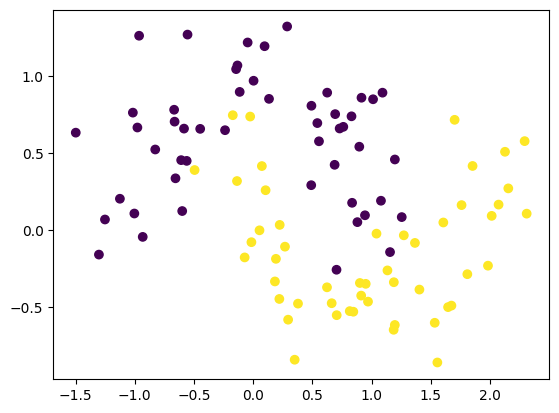

In [3]:
import matplotlib.pyplot as plt
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

In [4]:
model1 = Sequential()

model1.add(Dense(128,input_dim=2, activation="relu"))
model1.add(Dense(128, activation="relu"))
model1.add(Dense(1, activation='sigmoid'))

model1.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,025 (66.50 KB)

 Trainable params: 17,025 (66.50 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
adam = Adam(learning_rate=0.01)
model1.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])

history1 = model1.fit(X, y, epochs=2000, validation_split = 0.2, verbose=0) # 2000 epochs done so model overfits

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step


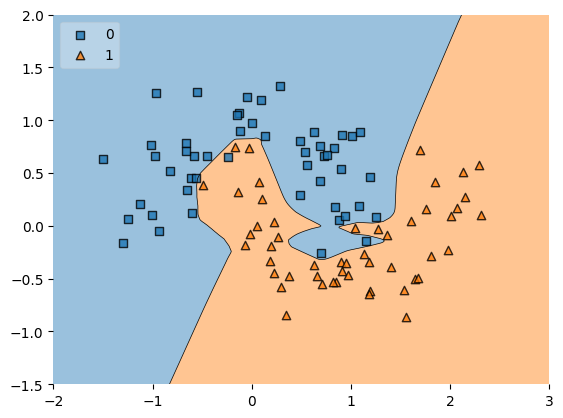

In [6]:
plot_decision_regions(X, y.astype('int'), clf=model1, legend=2)
plt.xlim(-2,3)
plt.ylim(-1.5,2)
plt.show()

# It can be seen that there is overfitting in the model

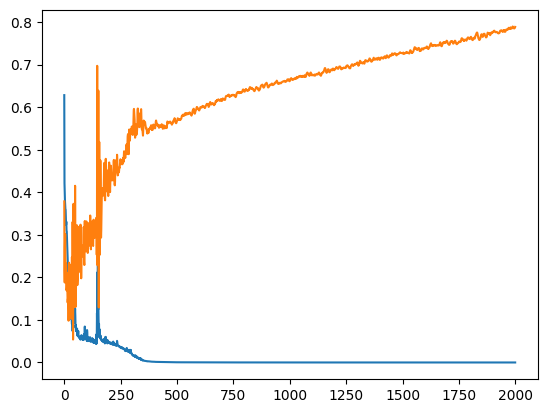

In [7]:
plt.plot(history1.history['loss'])
plt.plot(history1.history['val_loss'])

# It is seen that there is high validation loss because of overfitting

In [8]:
model2 = Sequential()

model2.add(Dense(128,input_dim=2, activation="relu", kernel_regularizer=tensorflow.keras.regularizers.l1(0.001)))
model2.add(Dense(128, activation="relu", kernel_regularizer=tensorflow.keras.regularizers.l1(0.001)))
model2.add(Dense(1, activation='sigmoid'))

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,025 (66.50 KB)

 Trainable params: 17,025 (66.50 KB)

 Non-trainable params: 0 (0.00 B)

# Now we run using regularization

In [9]:
adam = Adam(learning_rate=0.01)
model2.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])

history2 = model2.fit(X, y, epochs=2000, validation_split = 0.2, verbose=0)

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 13s 1ms/step


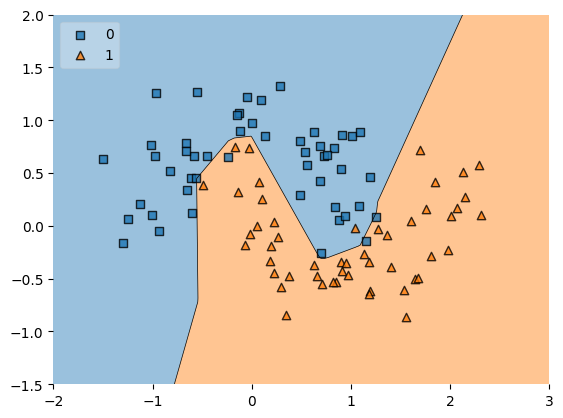

In [10]:
plot_decision_regions(X, y.astype('int'), clf=model2, legend=2)
plt.xlim(-2,3)
plt.ylim(-1.5,2)
plt.show()

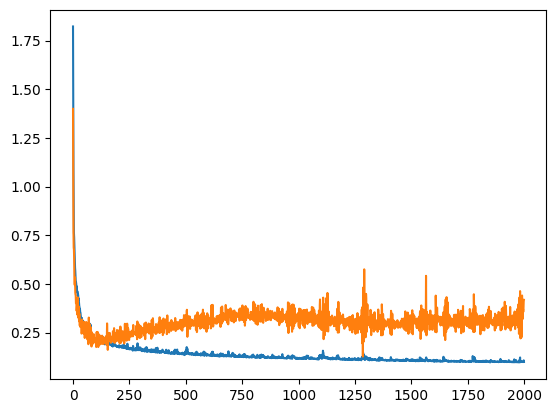

In [11]:
plt.plot(history2.history['loss'])
plt.plot(history2.history['val_loss'])

In [12]:
model1_weight_layer1 = model1.get_weights()[0].reshape(256)
model2_weight_layer1 = model2.get_weights()[0].reshape(256)

<Axes: >

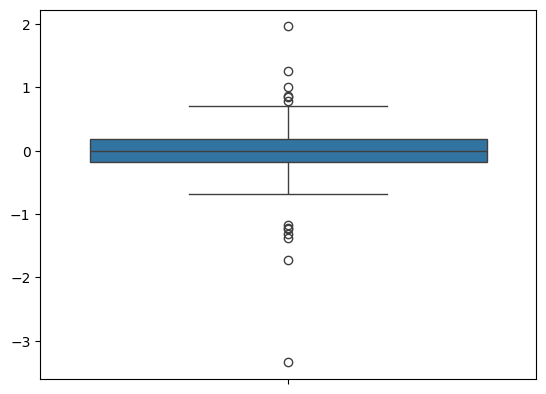

In [13]:
sns.boxplot(model1_weight_layer1)

<Axes: >

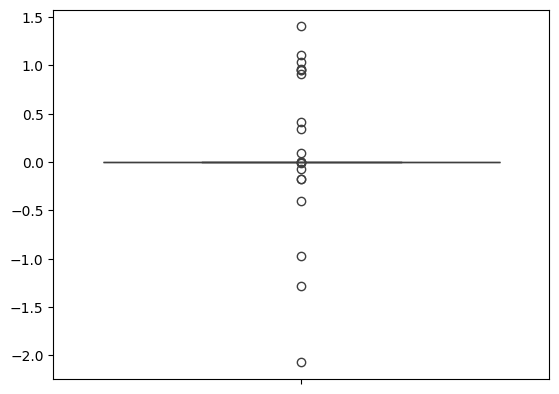

In [14]:
sns.boxplot(model2_weight_layer1)

In [15]:
model1_weight_layer1.min()

np.float32(-3.338769)

In [16]:
model2_weight_layer1.min()

np.float32(-2.0712302)

/tmp/ipykernel_12998/2224180084.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(model1_weight_layer1)
/tmp/ipykernel_12998/2224180084.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(model2_weight_layer1)


<Axes: ylabel='Density'>

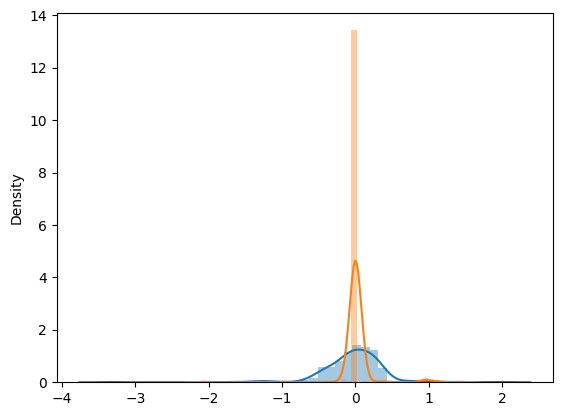

In [17]:
sns.distplot(model1_weight_layer1)
sns.distplot(model2_weight_layer1)

# Orange one is of regularization